In [113]:
import pandas as pd
import seaborn as sbn
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold

In [114]:
data = pd.read_csv("spotify-tracks-dataset-detailed.csv")


In [115]:
d = {}
m=0
for ids, rows in data.iterrows():
    genre = rows["track_genre"]
    if genre not in d:
        d[genre] = m
        m += 1
    data.loc[ids,"track_genre"] = d[genre]

In [116]:
d = {}
m=0
for ids, rows in data.iterrows():
    genre = rows["track_name"]
    if genre not in d:
        d[genre] = m
        m += 1
    data.loc[ids,"track_name"] = d[genre]

In [117]:
Y = data[["popularity"]]
X = data[["track_name","duration_ms","explicit","danceability","energy","key","loudness","mode","speechiness","acousticness","instrumentalness","liveness","valence","tempo","time_signature","track_genre"]]

<Axes: >

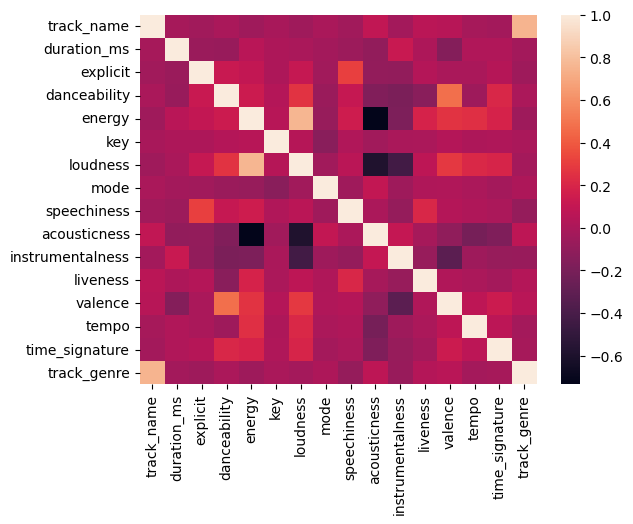

In [118]:
C = X.corr()
sbn.heatmap(C)

In [119]:
X = X.to_numpy()

In [120]:
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [121]:
pca = PCA(n_components=2)
x = pca.fit_transform(X)

(114000, 16) (114000, 1)


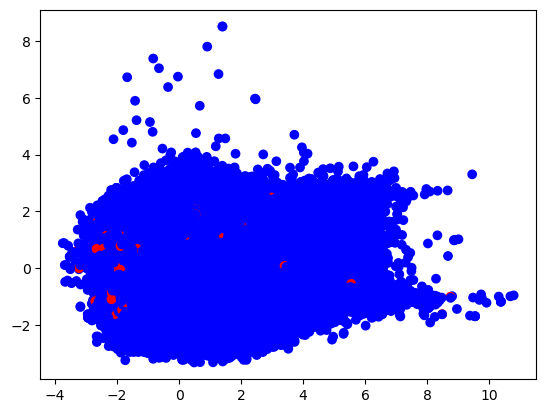

In [122]:
print(X.shape, Y.shape)
Y = np.ravel(Y)
couleurs = np.where(Y > 75, "red", "blue")
plt.scatter(x[:, 0], x[:, 1], c=couleurs)
plt.show()

In [123]:
pca = PCA(n_components=3)
x = pca.fit_transform(X)

(114000, 16) (114000,)


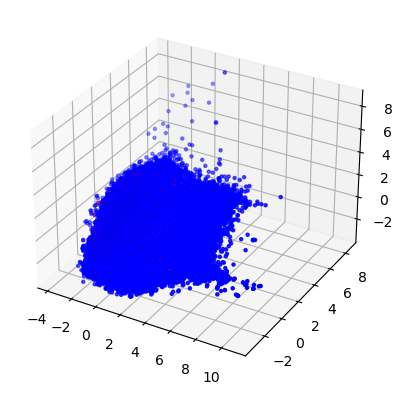

In [124]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
print(X.shape, Y.shape)
Y = np.ravel(Y)
couleurs = np.where(Y > 75, "red", "blue")
ax.scatter(x[:, 0], x[:, 1], x[:, 1], c=couleurs, marker = '.')
plt.show()

In [125]:
E = []
regressor = LinearRegression()
kf = KFold(n_splits=5,shuffle=True,random_state=0)
for train, test in kf.split(X):
    X_train, y_train = X[train], Y[train]
    X_test, y_test = X[test], Y[test]

    regressor.fit(X_train,y_train)
    y_pred = regressor.predict(X_test)
    E.append(np.sum(np.abs((y_pred-y_test)))/len(y_pred))
print(E)

[18.36042771016222, 18.405942405215892, 18.3709323643643, 18.30365705081316, 18.391656477501172]


In [126]:
E = []
pca = PCA(n_components=2)
x = pca.fit_transform(X)
regressor = LinearRegression()
kf = KFold(n_splits=5,shuffle=True,random_state=0)
for train, test in kf.split(X):
    X_train, y_train = x[train], Y[train]
    X_test, y_test = x[test], Y[test]

    regressor.fit(X_train,y_train)
    y_pred = regressor.predict(X_test)
    E.append(np.sum(np.abs((y_pred-y_test)))/len(y_pred))
print(E)

[18.839580610360994, 18.880160112887964, 18.850968334696255, 18.74236124873396, 18.826928402432472]


In [127]:
E = []
pca = PCA(n_components=1)
x = pca.fit_transform(X)
regressor = LinearRegression()
kf = KFold(n_splits=5,shuffle=True,random_state=0)
for train, test in kf.split(X):
    X_train, y_train = x[train], Y[train]
    X_test, y_test = x[test], Y[test]

    regressor.fit(X_train,y_train)
    y_pred = regressor.predict(X_test)
    E.append(np.sum(np.abs((y_pred-y_test)))/len(y_pred))
print(E)

[18.882994922920577, 18.92345424345666, 18.89032243699762, 18.784726652176918, 18.873013042529944]


In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_val_score
base = -cross_val_score(DummyRegressor(strategy="mean"), X, Y, cv=kf,scoring="neg_mean_absolute_error")
print(base.mean())

18.883979580255463


In [ ]:
# Conclusion : Modele lineaire n'est pas suffisant pour prédire la popularité en fonction des features pris